# 03 — Nettoyage : la couche silver

**But de ce notebook.** Passer des mesures brutes (bronze) à des **heures propres et alignées** (silver) : une ligne
par capteur, segment de position et heure UTC, avec la référence EEA, l'humidité officielle et, quand elle est
fiable, l'humidité de la sonde du capteur. On montre chaque règle, pourquoi elle existe et ce qu'elle retire.

Trois principes, décidés avec le commanditaire :

1. **On ne supprime aucune ligne.** Chaque mesure (ou heure) reçoit un **statut** `quality_flag` : `ok` ou la
   *première* règle qu'elle ne respecte pas. Le **rapport d'entonnoir** (`reports/funnel.md`) est calculé à partir de
   ces statuts, règle après règle.
2. **Uniquement des règles physiques et de cohérence**, chacune justifiée par les données. **Aucun filtre
   statistique d'aberrations** (z-score, écart interquartile…) sur les particules : les pics par forte humidité sont
   exactement ce que le modèle doit apprendre à corriger.
3. **L'humidité officielle (DWD, Météo-France) devient l'entrée principale** ; l'humidité de la sonde du capteur n'est
   qu'une variable secondaire, présente quand elle est fiable (notebook 02 : 39 % des heures-sondes seulement).

Vocabulaire :

- **Segment de position** : période continue pendant laquelle un capteur reste au même endroit (même site, mêmes
  coordonnées). Un capteur déménagé a plusieurs segments, appariés chacun à leur station.
- **Paire** : un segment de capteur et sa station de référence. **Heure-paire** : une heure d'une paire.
- **Cadence** : intervalle typique entre deux mesures d'un capteur (≈ 145 s pour la plupart, mais pas tous).
- **Complétude** d'une heure : nombre de mesures valides divisé par le nombre attendu à la cadence du capteur.

Commandes : `python -m aircalib silver` (nettoyage de chaque source) puis `python -m aircalib pair` (appariement,
jointures, contrôle d'horloge, entonnoir). Code : `src/aircalib/transform/` (règles) et `src/aircalib/silver/`.

## 0. Préparation

**Ce qu'on fait.** On charge la configuration, les modules de règles et les tables silver.

**Pourquoi.** Toute la logique est dans `src/` : le notebook montre et vérifie, il ne recalcule pas le nettoyage.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from aircalib.config import get_settings
from aircalib.silver import report
from aircalib.transform import clock
from aircalib.transform import particles as pt

SAMPLE = False
settings = get_settings().for_sample() if SAMPLE else get_settings()
B, S = settings.paths.bronze, settings.paths.silver
SC, PAIRS = S / "sensor_community", S / "pairs"
FIG_DIR = settings.paths.reports_dir / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pl.Config.set_engine_affinity("streaming")
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(14)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_fmt_str_lengths(80)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("période :", settings.period.start, "→", settings.period.end, "| silver :", S)

période : 2024-01-01 → 2025-12-31 | silver : /Users/leoweiss/Desktop/PROJET/air-calib/data/silver


## 1. Les mesures de particules (SDS011)

**Ce qu'on fait.** Chaque mesure brute reçoit son statut, dans cet ordre (`transform/particles.py`) :

| règle | condition | pourquoi |
|---|---|---|
| `pm_missing` | PM10 ou PM2.5 vide ou `NaN` | pas de mesure |
| `duplicate` | même horodatage et mêmes valeurs qu'une mesure précédente | copie : la première est gardée |
| `duplicate_conflict` | même horodatage, valeurs différentes | impossible de savoir laquelle est vraie : toutes écartées |
| `pm_negative` | PM < 0 | une concentration est positive (le firmware écrit −1/−1 en cas d'erreur) |
| `pm_saturated` | PM2.5 ≥ 999,9 ou PM10 ≥ 1 999,9 | signature du plafond du capteur, vue dans l'archive |
| `pm_above_range` | PM > 999,9 µg/m³ | hors de la plage de mesure du SDS011 |
| `pm25_above_pm10` | PM2.5 > PM10 | incohérent : PM2.5 est une partie de PM10 |
| `pm_stuck` | (PM10, PM2.5) identiques ≥ 1 h **et** (code de panne 0/0 **ou** station qui varie ≥ 5 µg/m³) | capteur figé (voir 1.2 et 1.3) |

**Pourquoi cet ordre.** Une mesure est comptée dans la *première* règle qu'elle viole, pour que l'entonnoir
additionne sans double compte. Les règles « structurelles » (vide, doublon) passent avant les règles physiques.

In [2]:
particle_funnel = report._explain(report.particle_funnel(settings), report.PARTICLE_REASONS)
particle_funnel.with_columns(pct_retiré=(100 * pl.col("removed") / pl.col("remaining").first()).round(3))

step,raison,removed,remaining,capteurs_lost,capteurs_remaining,segments_lost,segments_remaining,pct_retiré
str,str,i64,i64,i64,i64,i64,i64,f64
"""start""","""point de départ""",0,377950455,0,1399,0,1479,0.0
"""pm_missing""","""PM10 ou PM2.5 vide / NaN""",794913,377155542,1,1398,2,1477,0.21
"""duplicate""","""doublon exact (même horodatage, mêmes valeurs) : la 1re copie est gardée""",156,377155386,0,1398,0,1477,0.0
"""duplicate_conflict""","""même horodatage, valeurs différentes : impossible de choisir""",3286,377152100,0,1398,0,1477,0.001
"""pm_negative""","""valeur négative (code d'erreur −1 du firmware)""",447649,376704451,0,1398,0,1477,0.118
"""pm_saturated""","""saturation du capteur (PM2.5 = 999,9 avec PM10 = 1 999,9)""",2619590,374084861,2,1396,2,1475,0.693
"""pm_above_range""","""au-delà de la plage du SDS011 (999,9 µg/m³)""",196594,373888267,0,1396,0,1475,0.052
"""pm25_above_pm10""","""PM2.5 > PM10 : incohérent (PM2.5 fait partie de PM10)""",786986,373101281,0,1396,0,1475,0.208
"""pm_stuck""","""valeurs identiques ≥ 1 h ET (code de panne 0/0 OU station qui varie ≥ 5 µg/m³) :…",2555802,370545479,0,1396,0,1475,0.676


In [3]:
readings = pl.scan_parquet(SC / "pm" / "*.parquet").with_columns(pl.col("quality_flag").cast(pl.String))
by_sensor = (
    readings.filter(pl.col("quality_flag") != pt.OK)
    .group_by("quality_flag")
    .agg(mesures=pl.len(), capteurs=pl.col("sensor_id").n_unique())
    .collect()
)
concentration = (
    readings.filter(pl.col("quality_flag") != pt.OK)
    .group_by("quality_flag", "sensor_id")
    .agg(n=pl.len())
    .sort("n", descending=True)
    .group_by("quality_flag", maintain_order=True)
    .agg(part_des_2_premiers_capteurs=(pl.col("n").head(2).sum() / pl.col("n").sum()).round(3))
    .collect()
)
by_sensor.join(concentration, on="quality_flag").sort("mesures", descending=True)

quality_flag,mesures,capteurs,part_des_2_premiers_capteurs
str,u32,u32,f64
"""pm_saturated""",2619590,360,0.237
"""pm_stuck""",2555802,178,0.257
"""pm_missing""",794913,248,0.926
"""pm25_above_pm10""",786986,18,0.999
"""pm_negative""",447649,10,0.886
"""pm_above_range""",196594,565,0.402
"""duplicate_conflict""",3286,23,0.861
"""duplicate""",156,5,0.981


**Ce qu'on observe.** Sur 377,95 millions de mesures, **7,41 millions (2,0 %) sont écartées**, et aucune règle
ne fait disparaître à elle seule plus de 2 capteurs. Les deux plus grosses causes sont des pannes franches : capteurs
**saturés** (2,62 M, 360 capteurs) et **figés** (2,56 M, 178 capteurs). Plusieurs règles ne touchent qu'une poignée
de capteurs : PM2.5 > PM10 vient à 99,9 % de 2 capteurs (dont le 76986, incohérent en permanence), le code −1/−1 de
10 capteurs, les doublons en conflit de 23 capteurs. Le dépassement de plage (> 999,9 µg/m³) est au contraire réparti
sur 565 capteurs, avec des pics l'été 2024 (une dizaine de capteurs par jour) ; le Nouvel An n'en pèse que 0,4 %.
La cause (encrassement, insectes ?) n'est pas établie : ces valeurs sont simplement hors de ce que le SDS011 sait
mesurer. Les « doublons » vus à l'étape 2 étaient en majorité des lignes vides jumelles d'une
mesure : elles tombent dans `pm_missing`, et la mesure réelle est gardée. Aucun filtre statistique : un pic à
850 µg/m³ dans de l'air propre reste `ok` (test `test_no_statistical_outlier_filter`).

### 1.1 Exemple : un capteur saturé, un capteur incohérent

**Ce qu'on fait.** On trace deux capteurs réels avec leurs statuts : le 23046 (bloqué au plafond 999,9 / 1 999,9) et
le 76986 (PM2.5 > PM10 en permanence).

**Pourquoi.** Montrer que ces règles touchent des pannes franches, pas des pics plausibles.

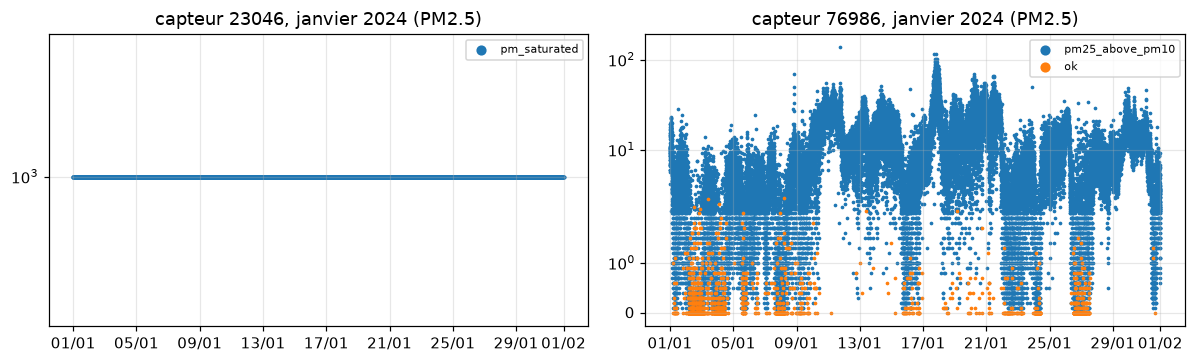

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, sensor_id in zip(axes, (23046, 76986), strict=True):
    path = SC / "pm" / f"{sensor_id}.parquet"
    if not path.exists():
        ax.set_title(f"capteur {sensor_id} absent de ce mode")
        continue
    one = (
        pl.read_parquet(path)
        .with_columns(pl.col("quality_flag").cast(pl.String))
        .filter(pl.col("timestamp").dt.month() == 1, pl.col("timestamp").dt.year() == 2024)
    )
    for flag, part in one.group_by("quality_flag"):
        ax.scatter(part["timestamp"], part["P2"], s=2, label=flag[0])
    ax.set_yscale("symlog")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.set_title(f"capteur {sensor_id}, janvier 2024 (PM2.5)")
    ax.legend(fontsize=7, markerscale=4)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_exemples_statuts.png")

### 1.2 Pourquoi « figé » commence à 1 heure

**Ce qu'on fait.** On reconstitue toutes les **séries de valeurs identiques** consécutives de chaque capteur, on les
classe par valeur et par durée, et on regarde ce que mesurait la station de référence pendant ce temps.

**Pourquoi.** Un compteur optique dans l'air réel fluctue d'une mesure à l'autre. Si un capteur répète exactement la
même valeur pendant des heures alors que la station voit une pollution ordinaire, il ne mesure plus. Le seuil
`particles.stuck_min_hours` doit séparer ces pannes des petits plateaux possibles en air très propre.

In [5]:
eea = pl.read_parquet(S / "eea" / "hourly.parquet").filter(
    pl.col("pollutant") == "pm25", pl.col("quality_flag") == "ok"
)
pairs_plan = pl.read_parquet(B / "reference" / "pairs.parquet").select("sensor_id", "sampling_point")
runs = []
for sensor_id in pairs_plan["sensor_id"].to_list():
    path = SC / "pm" / f"{sensor_id}.parquet"
    if not path.exists():
        continue
    one = pl.read_parquet(path, columns=["sensor_id", "timestamp", "P1", "P2", "quality_flag"]).with_columns(
        pl.col("quality_flag").cast(pl.String)
    )
    one = one.filter(pl.col("quality_flag").is_in([pt.OK, pt.PM_STUCK, pt.PM_SATURATED, pt.PM_NEGATIVE]))
    t = pl.col("timestamp")
    same = (pl.col("P1") == pl.col("P1").shift()) & (pl.col("P2") == pl.col("P2").shift())
    one = one.with_columns(run=(~same.fill_null(False)).cum_sum())
    runs.append(
        one.group_by("sensor_id", "run")
        .agg(n=pl.len(), t0=t.min(), t1=t.max(), p1=pl.col("P1").first(), p2=pl.col("P2").first())
        .filter(pl.col("n") >= 5)
    )
runs = pl.concat(runs).with_columns(hours=(pl.col("t1") - pl.col("t0")).dt.total_seconds() / 3600)
runs = runs.filter(pl.col("hours") >= 0.5).join(pairs_plan, on="sensor_id")
during = (
    runs.with_columns(
        hour=pl.datetime_ranges(pl.col("t0").dt.truncate("1h"), pl.col("t1").dt.truncate("1h"), "1h")
    )
    .explode("hour")
    .join(eea.select("sampling_point", "hour", "value"), on=["sampling_point", "hour"])
    .group_by("sensor_id", "run")
    .agg(station_médiane=pl.col("value").median())
)
runs = runs.join(during, on=["sensor_id", "run"], how="left").with_columns(
    valeur=pl.when(pl.col("p2") >= 999.9)
    .then(pl.lit("999,9 (saturé)"))
    .when(pl.col("p2") < 0)
    .then(pl.lit("−1 (erreur)"))
    .when((pl.col("p1") == 0) & (pl.col("p2") == 0))
    .then(pl.lit("0 / 0"))
    .when(pl.col("p2") < 1)
    .then(pl.lit("< 1 µg/m³"))
    .otherwise(pl.lit("≥ 1 µg/m³")),
    durée=pl.when(pl.col("hours") < 1)
    .then(pl.lit("a. 30 min – 1 h"))
    .when(pl.col("hours") < 3)
    .then(pl.lit("b. 1 – 3 h"))
    .when(pl.col("hours") < 24)
    .then(pl.lit("c. 3 – 24 h"))
    .otherwise(pl.lit("d. ≥ 24 h")),
)
runs.group_by("valeur", "durée").agg(
    séries=pl.len(),
    mesures=pl.col("n").sum(),
    capteurs=pl.col("sensor_id").n_unique(),
    station_médiane=pl.col("station_médiane").median().round(1),
).sort("valeur", "durée")

valeur,durée,séries,mesures,capteurs,station_médiane
str,str,u32,u32,u32,f64
"""0 / 0""","""a. 30 min – 1 h""",25915,434005,183,5.3
"""0 / 0""","""b. 1 – 3 h""",12595,455527,152,5.1
"""0 / 0""","""c. 3 – 24 h""",3955,622324,101,6.0
"""0 / 0""","""d. ≥ 24 h""",384,1226130,42,6.6
"""999,9 (saturé)""","""a. 30 min – 1 h""",393,7296,65,6.1
"""999,9 (saturé)""","""b. 1 – 3 h""",457,18651,63,6.3
"""999,9 (saturé)""","""c. 3 – 24 h""",504,106804,55,6.9
"""999,9 (saturé)""","""d. ≥ 24 h""",140,2306416,36,6.9
"""< 1 µg/m³""","""a. 30 min – 1 h""",32374,523276,210,6.0


**Ce qu'on observe.** Le tableau justifie la durée d'une heure. Les longues séries identiques sont **toutes**
des valeurs de panne : 0/0, moins de 1 µg/m³, le code −1 ou le plafond 999,9. Pendant ce temps, la station de
référence mesure une pollution ordinaire (médiane 5 à 7 µg/m³) : le capteur ne mesure plus. À l'inverse, une valeur
**≥ 1 µg/m³** ne se répète presque jamais pendant une heure (14 séries de 1 à 3 h sur 6 capteurs, pour 1 399
capteurs sur deux ans). Les séries de moins d'une heure à 0/0 ou à moins de 1 µg/m³ (≈ 0,96 million de mesures)
sont **gardées**. Mais la durée seule ne suffit pas : la section suivante vérifie que la règle ne vise pas l'air propre.

### 1.3 Vérification : la règle touche-t-elle l'air très propre ?

**Ce qu'on fait.** En air propre, un SDS011 peut légitimement répéter 0,3 ou 0,5 µg/m³. On prend toutes les heures
couvertes par un plateau d'au moins une heure (hors saturation et code −1, déjà traités) et on compare la valeur EEA de
ces heures à celle des heures gardées. Puis on applique la règle retenue :

- plateau d'un **code de panne connu** (0/0 ; −1 et 999,9 sont déjà écartés plus haut) → figé ;
- sinon, figé **seulement si la station a varié d'au moins 5 µg/m³** pendant le plateau
  (`particles.stuck_reference_range_ugm3`, la même borne que le bruit des analyseurs EEA autour de zéro) ;
- sinon (air calme, station stable, ou station inconnue) → la mesure est gardée.

**Pourquoi.** Une règle de panne ne doit pas retirer en priorité les heures d'air propre : ce serait un biais vers
les fortes concentrations, que le modèle apprendrait ensuite.

In [6]:
limit = settings.particles.stuck_min_hours
plateaus = runs.filter(
    pl.col("hours") >= limit, pl.col("p2") >= 0, pl.col("p2") < settings.particles.pm25_saturation_ugm3
)
plateau_hours = (
    plateaus.with_columns(
        hour=pl.datetime_ranges(pl.col("t0").dt.truncate("1h"), pl.col("t1").dt.truncate("1h"), "1h")
    )
    .explode("hour")
    .join(eea.select("sampling_point", "hour", "value"), on=["sampling_point", "hour"])
)
moves = plateau_hours.group_by("sensor_id", "run").agg(
    station_range=pl.col("value").max() - pl.col("value").min()
)
code = pl.any_horizontal(
    [(pl.col("p1") == a) & (pl.col("p2") == b) for a, b in settings.particles.stuck_codes]
)
verdict = (
    plateaus.join(moves, on=["sensor_id", "run"], how="left")
    .with_columns(
        verdict=pl.when(code)
        .then(pl.lit("figé : code 0/0"))
        .when(pl.col("station_range") >= settings.particles.stuck_reference_range_ugm3)
        .then(pl.lit("figé : la station a varié"))
        .otherwise(pl.lit("gardé : air calme"))
    )
    .select("sensor_id", "run", "verdict", "n")
)
plateau_hours = plateau_hours.join(verdict, on=["sensor_id", "run"])
kept = pl.read_parquet(PAIRS / "pair_hours.parquet", columns=["status", "ref_pm25"]).filter(
    pl.col("status") == "ok"
)


def describe(frame: pl.DataFrame, label: str) -> pl.DataFrame:
    v = pl.col("value") if "value" in frame.columns else pl.col("ref_pm25")
    return frame.select(
        groupe=pl.lit(label),
        heures=pl.len(),
        médiane=v.median().round(1),
        q25=v.quantile(0.25).round(1),
        part_sous_3=(v < 3).mean().round(3),
        part_sous_5=(v < 5).mean().round(3),
    )


print(verdict.group_by("verdict").agg(plateaux=pl.len(), mesures=pl.col("n").sum()).sort("verdict"))
pl.concat(
    [
        describe(kept, "heures gardées (référence)"),
        describe(plateau_hours, "toutes les heures de plateaux ≥ 1 h"),
        *[describe(part, label[0]) for label, part in plateau_hours.group_by("verdict", maintain_order=True)],
    ]
)

shape: (3, 3)
┌───────────────────────────┬──────────┬─────────┐
│ verdict                   ┆ plateaux ┆ mesures │
│ ---                       ┆ ---      ┆ ---     │
│ str                       ┆ u32      ┆ u32     │
╞═══════════════════════════╪══════════╪═════════╡
│ figé : code 0/0           ┆ 16934    ┆ 2303981 │
│ figé : la station a varié ┆ 746      ┆ 265082  │
│ gardé : air calme         ┆ 12163    ┆ 514083  │
└───────────────────────────┴──────────┴─────────┘


groupe,heures,médiane,q25,part_sous_3,part_sous_5
str,u32,f64,f64,f64,f64
"""heures gardées (référence)""",13822352,7.2,4.5,0.111,0.297
"""toutes les heures de plateaux ≥ 1 h""",174144,6.2,3.9,0.147,0.369
"""figé : code 0/0""",131070,6.3,4.0,0.146,0.36
"""gardé : air calme""",32969,5.6,3.6,0.158,0.42
"""figé : la station a varié""",10105,7.4,4.0,0.129,0.31


**Ce qu'on observe.** **Oui, la durée seule visait trop l'air propre.** Sur les heures couvertes par un
plateau d'au moins une heure, 36,9 % ont une valeur EEA sous 5 µg/m³ (14,7 % sous 3), contre 29,7 % (11,1 %) pour
les heures gardées. La règle retenue sépare trois cas :

- **plateaux 0/0** (16 934 plateaux, 2,30 M mesures) : toujours figés. Ils penchent un peu vers l'air propre
  (36 % sous 5 µg/m³), mais la station mesure 6,3 µg/m³ en médiane pendant que le capteur affiche zéro : ce n'est pas
  une mesure, c'est un capteur qui ne voit plus rien ;
- **plateaux d'une autre valeur pendant lesquels la station a varié d'au moins 5 µg/m³** (746 plateaux, 0,27 M
  mesures) : figés. Leur distribution est maintenant **celle des heures gardées** (31 % sous 5 µg/m³, médiane 7,4) ;
- **plateaux en air calme** (12 163 plateaux, 0,51 M mesures) : **gardés**. Ce sont bien les heures les plus propres
  (42 % sous 5 µg/m³, médiane 5,6), qui auraient été retirées à tort.

La règle ne retire donc plus en priorité l'air propre, à l'exception assumée des plateaux à zéro.

## 2. Agrégation horaire : complétude selon la cadence propre de chaque capteur

**Ce qu'on fait.** Pour chaque capteur et chaque mois, la **cadence** est la médiane des écarts entre mesures
consécutives (en ignorant les coupures de plus d'une heure). À chaque heure, on calcule à partir des seules mesures
`ok` la moyenne, la médiane, l'écart-type et le nombre de mesures (futures variables), et la complétude :

$$
\text{complétude} = \frac{n_{\text{valides}}}{3600 / \text{cadence}}
$$

Une heure est gardée si sa complétude atteint **75 %** (`particles.min_completeness`).

**Pourquoi.** Les capteurs n'envoient pas tous au même rythme (de 1 à 5 minutes). Un seuil fixe en nombre de
mesures (« au moins 18 par heure ») éliminerait à tort tous les capteurs lents et laisserait passer des heures à
moitié vides chez les capteurs rapides.

cadence médiane par capteur (s) : 125.0 / 146.0 / 301.0 (5 % / médiane / 95 %)
shape: (6, 2)
┌────────┬──────┐
│ classe ┆ len  │
│ ---    ┆ ---  │
│ f64    ┆ u32  │
╞════════╪══════╡
│ 150.0  ┆ 1146 │
│ 180.0  ┆ 69   │
│ 300.0  ┆ 55   │
│ 60.0   ┆ 35   │
│ 120.0  ┆ 21   │
│ 240.0  ┆ 15   │
└────────┴──────┘


hour_flag,heures,part
str,u32,f64
"""ok""",14637759,0.9342
"""incomplete_hour""",800252,0.0511
"""no_valid_reading""",230389,0.0147


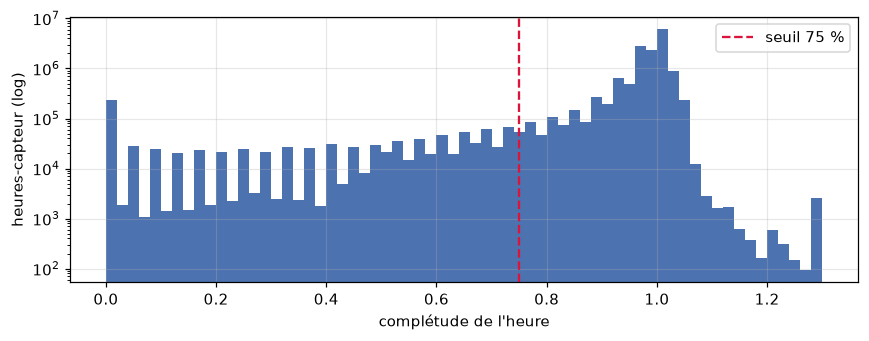

In [7]:
pm_hourly = pl.read_parquet(SC / "pm_hourly.parquet")
cadence = pm_hourly.group_by("sensor_id").agg(cadence_s=pl.col("cadence_s").median())
print(
    "cadence médiane par capteur (s) :",
    cadence["cadence_s"].quantile(0.05),
    "/",
    cadence["cadence_s"].median(),
    "/",
    cadence["cadence_s"].quantile(0.95),
    "(5 % / médiane / 95 %)",
)
print(
    cadence.group_by(classe=(pl.col("cadence_s") / 30).round() * 30)
    .len()
    .sort("len", descending=True)
    .head(6)
)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(pm_hourly["completeness"].drop_nulls().clip(0, 1.3), bins=65, color="#4C72B0")
ax.axvline(settings.particles.min_completeness, color="crimson", ls="--", label="seuil 75 %")
ax.set_yscale("log")
ax.set_xlabel("complétude de l'heure")
ax.set_ylabel("heures-capteur (log)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_completude_horaire.png")
pm_hourly.group_by("hour_flag").agg(heures=pl.len()).with_columns(
    part=(pl.col("heures") / pl.col("heures").sum()).round(4)
)

In [8]:
lost = (
    pm_hourly.filter(pl.col("hour_flag") == pt.NO_VALID_READING)
    .group_by("main_flag")
    .agg(heures=pl.len())
    .sort("heures", descending=True)
)
lost.with_columns(part=(pl.col("heures") / pl.col("heures").sum()).round(3))

main_flag,heures,part
str,u32,f64
"""pm_saturated""",108743,0.472
"""pm_stuck""",78222,0.34
"""pm_negative""",28198,0.122
"""pm25_above_pm10""",9916,0.043
"""pm_above_range""",5201,0.023
"""pm_missing""",109,0.0


**Ce qu'on observe.** La cadence médiane est de **146 s**, mais 5 % des capteurs envoient toutes les 125 s ou
moins et 5 % toutes les 300 s ou plus (60 s, 120 s, 180 s, 240 s, 300 s existent) : environ 250 capteurs n'ont pas la
cadence standard de ≈ 150 s, et un seuil fixe en nombre de mesures les aurait mal jugés. Sur 15,67 millions d'heures-capteur, **93,4 % sont complètes**, 5,1 % sont
incomplètes (< 75 %) et 1,5 % n'ont aucune mesure valide. Pour ces dernières, la raison dominante est la saturation
(47 %), puis le capteur figé (34 %) et le code d'erreur −1 (12 %). Chaque heure gardée conserve la moyenne, la
médiane, l'écart-type et le nombre de mesures valides de PM2.5 et PM10 (variables de l'étape 5).

## 3. Segments de position : un appariement par segment

**Ce qu'on fait.** On découpe chaque capteur en **segments** (suites de mesures au même site et aux mêmes
coordonnées ; revenir à une ancienne position ouvre un nouveau segment), puis on apparie **chaque segment** avec la
règle de l'étape 1 : la station la plus proche à ≤ 3 km ayant des heures vérifiées pendant les mois du segment.

**Pourquoi.** La paire avait été calculée sur la position la plus récente du capteur. Un capteur déménagé peut avoir
changé de station, ou n'en avoir aucune à portée pendant une partie de la période.

In [9]:
segments = pl.read_parquet(PAIRS / "segment_pairs.parquet")
planned = pl.read_parquet(B / "reference" / "pairs.parquet").select(
    "sensor_id", planned_point="sampling_point"
)
segments = segments.join(planned, on="sensor_id", how="left").with_columns(
    situation=pl.when(pl.col("pair_status") != "ok")
    .then(pl.col("pair_status"))
    .when(pl.col("sampling_point") == pl.col("planned_point"))
    .then(pl.lit("même station que prévu"))
    .otherwise(pl.lit("autre station"))
)
moved = segments.filter(pl.col("segment") > 1)["sensor_id"].n_unique()
n_sensors = segments["sensor_id"].n_unique()
print(f"{segments.height} segments pour {n_sensors} capteurs ; capteurs déplacés : {moved}")
print(
    segments.group_by("situation").agg(
        segments=pl.len(), capteurs=pl.col("sensor_id").n_unique(), mesures=pl.col("n_readings").sum()
    )
)
segments.filter(pl.col("situation") != "même station que prévu").select(
    "sensor_id",
    "segment",
    "start",
    "end",
    "lat",
    "lon",
    "sampling_point",
    "distance_km",
    "planned_point",
    "situation",
).sort("start").head(15)

1479 segments pour 1399 capteurs ; capteurs déplacés : 65
shape: (3, 4)
┌────────────────────────┬──────────┬──────────┬───────────┐
│ situation              ┆ segments ┆ capteurs ┆ mesures   │
│ ---                    ┆ ---      ┆ ---      ┆ ---       │
│ str                    ┆ u32      ┆ u32      ┆ u32       │
╞════════════════════════╪══════════╪══════════╪═══════════╡
│ no_reference_station   ┆ 22       ┆ 19       ┆ 1012647   │
│ même station que prévu ┆ 1445     ┆ 1399     ┆ 375621751 │
│ autre station          ┆ 12       ┆ 10       ┆ 1316057   │
└────────────────────────┴──────────┴──────────┴───────────┘


sensor_id,segment,start,end,lat,lon,sampling_point,distance_km,planned_point,situation
i64,u32,datetime[μs],datetime[μs],f64,f64,str,f64,str,str
68184,1,2024-01-01 00:00:21,2024-06-28 09:05:59,48.7705,9.1372481,null,null,"""SPO.DE_DEBW081_PM2_dataGroup1""","""no_reference_station"""
42694,1,2024-01-01 00:00:34,2024-04-08 23:58:08,50.851567,4.349553,null,null,"""SPO.DE_DENW082_PM2_dataGroup1""","""no_reference_station"""
34433,1,2024-01-01 00:00:37,2024-04-18 15:18:40,48.562,13.384,null,null,"""SPO.DE_DEBY118_PM2_dataGroup1""","""no_reference_station"""
27263,1,2024-01-01 00:00:40,2024-03-08 19:26:48,52.499043,13.440547,"""SPO.DE_DEBE034_PM2_dataGroup1""",1.252892,"""SPO.DE_DEBE068_PM2_dataGroup1""","""autre station"""
81487,1,2024-01-01 00:00:59,2025-08-10 17:58:06,52.464,13.428,"""SPO.DE_DEBE127_PM2_dataGroup1""",0.974536,"""SPO.DE_DEBE010_PM2_dataGroup1""","""autre station"""
75419,1,2024-01-01 00:01:15,2024-03-31 10:02:51,52.488,13.428,"""SPO.DE_DEBE034_PM2_dataGroup1""",0.250943,"""SPO.DE_DEBE065_PM2_dataGroup1""","""autre station"""
35807,1,2024-01-01 00:01:21,2025-02-19 07:21:24,52.413698,13.27334,null,null,"""SPO.DE_DEBE069_PM2_dataGroup1""","""no_reference_station"""
45248,1,2024-01-01 00:01:48,2025-12-09 08:46:30,48.489218,9.214437,"""SPO.DE_DEBW147_PM2_dataGroup1""",0.269035,"""SPO.DE_DEBW027_PM2_dataGroup1""","""autre station"""
9232,1,2024-01-01 00:02:18,2024-07-09 19:50:09,52.52,13.464,"""SPO.DE_DEBE065_PM2_dataGroup1""",0.771878,"""SPO.DE_DESN077_PM2_dataGroup1""","""autre station"""


**Ce qu'on observe.** 1 479 segments pour 1 399 capteurs : 65 capteurs ont bougé. **1 445 segments** gardent la
station prévue ; **12 segments** (10 capteurs, 1,3 million de mesures) ont, pendant leur séjour à une autre adresse,
une **autre station** plus proche, déjà téléchargée car elle appartient à d'autres paires (souvent à Berlin, où les
stations sont serrées). **22 segments** (19 capteurs, 1,0 million de mesures) n'ont **aucune station utilisable à
3 km** : le capteur 84804 à Hanoï, le 42694 qui était à Bruxelles jusqu'en avril 2024, d'autres en périphérie des
villes. Leurs heures sont gardées avec le statut `no_reference_station` (42 902 heures-capteur). Sans ce découpage,
ces mesures auraient été comparées à une station située à des centaines ou des milliers de kilomètres.

## 4. La référence EEA

**Ce qu'on fait.** Heure UTC = `Start − 1 h` (mesuré à l'étape 1, vérifié à nouveau en section 6). Puis, par heure :
`invalid` (drapeau de validité refusé ou sentinelle −999), `not_verified`, `negative_beyond_uncertainty`.

**Pourquoi la règle sur les valeurs négatives.** Les analyseurs automatiques mesurent avec un bruit de quelques
µg/m³ autour de zéro : l'agence valide donc de petites valeurs négatives (0,18 % des heures PM2.5, médiane −0,8). Les
remplacer par 0 ou les retirer **biaiserait la cible vers le haut** en air propre : on les garde telles quelles. En
dessous de −5 µg/m³ (`eea.negative_floor_ugm3`), ce n'est plus du bruit : l'heure est écartée.

In [10]:
eea_all = pl.read_parquet(S / "eea" / "hourly.parquet")
negatives = eea_all.filter(pl.col("value") < 0, pl.col("value") != settings.eea.missing_sentinel)
print(
    negatives.group_by("pollutant", "quality_flag").agg(
        heures=pl.len(),
        points=pl.col("sampling_point").n_unique(),
        médiane=pl.col("value").median(),
        minimum=pl.col("value").min(),
    )
)
report._explain(report.reference_funnel(settings), report.REFERENCE_REASONS)

shape: (4, 6)
┌───────────┬─────────────────────────────┬────────┬────────┬─────────┬─────────┐
│ pollutant ┆ quality_flag                ┆ heures ┆ points ┆ médiane ┆ minimum │
│ ---       ┆ ---                         ┆ ---    ┆ ---    ┆ ---     ┆ ---     │
│ str       ┆ str                         ┆ u32    ┆ u32    ┆ f64     ┆ f64     │
╞═══════════╪═════════════════════════════╪════════╪════════╪═════════╪═════════╡
│ pm25      ┆ ok                          ┆ 8955   ┆ 36     ┆ -0.79   ┆ -4.901  │
│ pm10      ┆ negative_beyond_uncertainty ┆ 1      ┆ 1      ┆ -5.16   ┆ -5.16   │
│ pm10      ┆ ok                          ┆ 849    ┆ 32     ┆ -0.7    ┆ -4.441  │
│ pm25      ┆ negative_beyond_uncertainty ┆ 1      ┆ 1      ┆ -6.241  ┆ -6.241  │
└───────────┴─────────────────────────────┴────────┴────────┴─────────┴─────────┘


step,raison,removed,remaining,points_lost,points_remaining,polluant
str,str,i64,i64,i64,i64,str
"""start""","""point de départ""",0,5034394,0,298,"""pm25"""
"""invalid""","""drapeau de validité refusé ou sentinelle −999""",160414,4873980,0,298,"""pm25"""
"""not_verified""","""heure non vérifiée par l'agence""",0,4873980,0,298,"""pm25"""
"""negative_beyond_uncertainty""","""valeur < −5 µg/m³ (`eea.negative_floor_ugm3`) : au-delà du bruit autour de 0""",1,4873979,0,298,"""pm25"""
"""usable""","""**utilisable**""",0,4873979,0,298,"""pm25"""
"""start""","""point de départ""",0,4764209,0,277,"""pm10"""
"""invalid""","""drapeau de validité refusé ou sentinelle −999""",88798,4675411,0,277,"""pm10"""
"""not_verified""","""heure non vérifiée par l'agence""",0,4675411,0,277,"""pm10"""
"""negative_beyond_uncertainty""","""valeur < −5 µg/m³ (`eea.negative_floor_ugm3`) : au-delà du bruit autour de 0""",1,4675410,0,277,"""pm10"""


**Ce qu'on observe.** Sur 5,03 millions d'heures PM2.5 de la période, 3,2 % sont invalides (drapeau ou −999)
et **aucune n'est non vérifiée** (E1a). Les valeurs négatives validées sont rares (8 955 heures PM2.5, 36 points,
médiane −0,79, minimum −4,9) : elles sont gardées telles quelles. Une seule heure PM2.5 (−6,2) et une seule PM10
(−5,2) passent sous le seuil de −5 µg/m³ et sont écartées.

## 5. L'humidité : l'officielle en principal, la sonde en secondaire

### 5.1 Changement de stratégie

**Ce qu'on fait.** Le notebook 02 a montré que seules 39 % des heures-sondes sont utilisables et que même les sondes
saines lisent trop sec. On fait donc de l'**humidité officielle** (DWD, Météo-France) l'entrée **principale** : elle
existe pour toutes les paires. L'humidité de la sonde devient une variable **secondaire**, renseignée seulement
quand elle est fiable (`local_reliable`).

**Argument métier.** La correction n'exige pas que la sonde d'humidité du capteur fonctionne : un réseau de capteurs
à 30 € peut être corrigé avec la station météo publique la plus proche.

**Choix de la station officielle (par paire).** Parmi les deux stations retenues pour la station EEA, on prend la
plus proche **du capteur** ; si deux stations sont à moins de 0,5 km d'écart (`weather.tie_km`), la plus complète
gagne. Une heure manquante à la station choisie est prise à l'autre (`weather_fallback`).

In [11]:
choice = pl.read_parquet(PAIRS / "weather_choice.parquet")
main = choice.filter(pl.col("choice") == 1)
switched = main.filter(pl.col("weather_rank") != 1).height
print(f"paires : {main.height} ; station principale ≠ rang 1 de la station EEA : {switched}")
main.group_by("source").agg(
    paires=pl.len(),
    distance_médiane_km=pl.col("sensor_weather_km").median().round(1),
    q90_km=pl.col("sensor_weather_km").quantile(0.9).round(1),
    max_km=pl.col("sensor_weather_km").max().round(1),
)

paires : 1457 ; station principale ≠ rang 1 de la station EEA : 74


source,paires,distance_médiane_km,q90_km,max_km
str,u32,f64,f64,f64
"""dwd""",1309,6.4,12.8,24.8
"""meteo_france""",148,6.5,9.2,26.7


### 5.2 La sonde du capteur : statuts, valeurs figées, fiabilité

**Ce qu'on fait.** Statut de chaque mesure (notebook 02) plus une nouvelle règle : une valeur utilisable répétée à
l'identique pendant ≥ 3 h (`humidity.stuck_min_hours`) est **figée**. Une heure-sonde est **fiable** si sa valeur
est utilisable, que l'heure n'est pas en défaut et que le mois n'est pas « mort » (X = 0,3).

**Pourquoi 3 h.** Pendant les séries identiques de 3 h et plus, l'humidité officielle voisine a varié de 6 à
50 points en médiane, contre 2 points pour les séries de moins de 2 h.

In [12]:
humidity_readings, humidity_hours = report.humidity_funnels(settings)
print(report._explain(humidity_readings, report.PROBE_REASONS))
report._explain(humidity_hours, report.PROBE_REASONS)

shape: (7, 6)
┌──────────────┬───────────────────────────────────────────────────────────────┬───────────┬───────────┬─────────────┬──────────────────┐
│ step         ┆ raison                                                        ┆ removed   ┆ remaining ┆ sondes_lost ┆ sondes_remaining │
│ ---          ┆ ---                                                           ┆ ---       ┆ ---       ┆ ---         ┆ ---              │
│ str          ┆ str                                                           ┆ i64       ┆ i64       ┆ i64         ┆ i64              │
╞══════════════╪═══════════════════════════════════════════════════════════════╪═══════════╪═══════════╪═════════════╪══════════════════╡
│ start        ┆ point de départ                                               ┆ 0         ┆ 289721376 ┆ 0           ┆ 1127             │
│ missing      ┆ humidité vide / NaN                                           ┆ 2043899   ┆ 287677477 ┆ 1           ┆ 1126             │
│ out_of_range ┆ hum

step,raison,removed,remaining,sondes_lost,sondes_remaining
str,str,i64,i64,i64,i64
"""start""","""point de départ""",0,11988970,0,1126
"""dead_month""","""mois-sonde « mort » (> 30 % d'heures en défaut, `humidity.dead_month_share`)""",7144741,4844229,467,659
"""faulty_hour""","""heure en défaut (majorité des mesures non utilisables) dans un mois sain""",225809,4618420,0,659
"""usable""","""**utilisable**""",0,4618420,0,659


**Ce qu'on observe.** Humidité officielle : les 1 457 paires appariées ont une station officielle principale, à
**6,4 km** du capteur en médiane (DWD) et 6,5 km (Météo-France), 90 % à moins de 12,8 km. Pour **74 paires**, la
station la plus proche du capteur n'est pas la plus proche de la station EEA : elle devient la principale. Côté
sondes, 289,7 millions de mesures donnent 149,1 millions de mesures utilisables (51,5 %) ; la nouvelle règle
« figée ≥ 3 h » en retire 0,86 million. À l'heure, 4,62 millions d'heures-sondes sont fiables sur 11,99 (38,5 %) ;
467 sondes n'ont plus aucune heure fiable. Dans les heures-paires utilisables (section 7), l'humidité de la sonde
n'est fiable que **27 % du temps en Allemagne** et 32 à 46 % en France : c'est bien une variable secondaire.

## 6. Contrôle d'horloge automatique sur toutes les paires

**Ce qu'on fait.** Pour chaque paire, on corrèle la **variation d'une heure à l'autre** du PM2.5 du capteur à l'heure
$h$ avec celle de la station à l'heure $h+k$ :

$$
r(k) = \operatorname{corr}\big(\Delta\text{capteur}(h),\ \Delta\text{station}(h+k)\big),\qquad
\Delta x(h) = x(h) - x(h-1),\quad k \in \{-3,\dots,3\}
$$

Verdict (`clock.*`) : **invérifiable** si moins de 500 heures communes ou si même la meilleure corrélation est sous
0,1 (les variations ne portent pas d'information de temps) ; **retard d'instrument** si la station mesure avec un
TEOM et que le meilleur $k$ vaut +1 (voir plus bas : gardée) ; **décalage** si le meilleur $k$ n'est pas 0 **et**
bat $k = 0$ nettement :

$$
z = \big(\operatorname{atanh} r(k^\star) - \operatorname{atanh} r(0)\big)\sqrt{\tfrac{n-3}{2}} \ \ge\ 3
$$

($z$ de Fisher, comme si les deux corrélations étaient indépendantes : prudent ici). Le même test est fait **par
station**, en regroupant ses paires : les horodatages des capteurs viennent tous du même serveur, donc un problème
d'heure est un problème de station. Une paire est exclue si elle **ou** sa station est en décalage.

**Pourquoi les variations et pas les niveaux.** Les niveaux de pollution évoluent lentement (météo, jour/nuit) : la
corrélation des niveaux est presque plate entre $k = 0$ et $k = \pm 1$, et son maximum dépend du bruit ou du temps
de trajet d'un panache entre la station et le capteur. Le premier essai, sur les niveaux et sans test de
significativité, rejetait 4 paires sur 20 de l'échantillon et 171 sur 1 440 sur le volume complet. Exemple
ci-dessous : la paire 32200, excellente, comparée sur les niveaux et sur les variations.

In [13]:
hours = pl.read_parquet(
    PAIRS / "pair_hours.parquet",
    columns=[
        "pair_id",
        "station_code",
        "hour",
        "hour_flag",
        "pair_status",
        "ref_pm25_flag",
        "pm25_mean",
        "ref_pm25",
    ],
)
checkable = hours.filter(
    (pl.col("hour_flag") == "ok") & (pl.col("pair_status") == "ok") & (pl.col("ref_pm25_flag") == "ok")
).select("pair_id", "station_code", "hour", sensor="pm25_mean", reference="ref_pm25")
example = checkable.filter(pl.col("pair_id") == "32200-1")
if example.height:
    levels = clock.lag_correlations(example, 3).select("lag_h", niveaux="pearson_r")
    changes = clock.lag_correlations(clock.hourly_changes(example), 3).select("lag_h", variations="pearson_r")
    print(levels.join(changes, on="lag_h"))

shape: (7, 3)
┌───────┬──────────┬────────────┐
│ lag_h ┆ niveaux  ┆ variations │
│ ---   ┆ ---      ┆ ---        │
│ i32   ┆ f64      ┆ f64        │
╞═══════╪══════════╪════════════╡
│ -3    ┆ 0.829931 ┆ -0.020707  │
│ -2    ┆ 0.85289  ┆ 0.013782   │
│ -1    ┆ 0.875312 ┆ 0.117905   │
│ 0     ┆ 0.887993 ┆ 0.230854   │
│ 1     ┆ 0.884217 ┆ 0.180695   │
│ 2     ┆ 0.868152 ┆ 0.060654   │
│ 3     ┆ 0.847314 ┆ 0.018355   │
└───────┴──────────┴────────────┘


In [14]:
cfg = settings.clock
rows = []
for label, shift_h in (("avec la correction Start − 1 h", 0), ("contre-épreuve : sans correction", 1)):
    reference = checkable.select("pair_id", "hour", "reference").with_columns(
        hour=pl.col("hour") + pl.duration(hours=shift_h)
    )
    test = checkable.select("pair_id", "station_code", "hour", "sensor").join(
        reference, on=["pair_id", "hour"], how="full", coalesce=True
    )
    test = test.with_columns(pl.col("station_code").fill_null(strategy="forward").over("pair_id"))
    changes = clock.hourly_changes(test)
    per_pair = clock.clock_status(
        clock.lag_correlations(changes, cfg.max_lag_h), cfg.min_hours, cfg.min_r, cfg.min_z
    )
    per_station = clock.clock_status(
        clock.lag_correlations(changes, cfg.max_lag_h, group="station_code"),
        cfg.min_hours,
        cfg.min_r,
        cfg.min_z,
        group="station_code",
    )
    for level, table in (("paires", per_pair), ("stations", per_station)):
        counts = dict(table["clock_flag"].value_counts().iter_rows())
        rows.append(
            {
                "cas": label,
                "niveau": level,
                **{k: counts.get(k, 0) for k in ("ok", "clock_mismatch", "clock_unverifiable")},
            }
        )
pl.DataFrame(rows)

cas,niveau,ok,clock_mismatch,clock_unverifiable
str,str,i64,i64,i64
"""avec la correction Start − 1 h""","""paires""",1113,29,299
"""avec la correction Start − 1 h""","""stations""",209,7,81
"""contre-épreuve : sans correction""","""paires""",54,1085,298
"""contre-épreuve : sans correction""","""stations""",9,207,81


shape: (7, 8)
┌──────────────┬────────────────┬────────────────────┬─────────┬──────────┬────────────┬──────────┬───────────┐
│ station_code ┆ clock_flag     ┆ measurement_method ┆ n_hours ┆ r_lag0   ┆ best_lag_h ┆ r_best   ┆ z         │
│ ---          ┆ ---            ┆ ---                ┆ ---     ┆ ---      ┆ ---        ┆ ---      ┆ ---       │
│ str          ┆ str            ┆ str                ┆ u32     ┆ f64      ┆ i32        ┆ f64      ┆ f64       │
╞══════════════╪════════════════╪════════════════════╪═════════╪══════════╪════════════╪══════════╪═══════════╡
│ DEBY099      ┆ clock_mismatch ┆ nephelometry+beta  ┆ 7583    ┆ 0.104466 ┆ 1          ┆ 0.308755 ┆ 13.194212 │
│ DEMV007      ┆ clock_mismatch ┆ light-scat         ┆ 15647   ┆ 0.113742 ┆ -1         ┆ 0.154779 ┆ 3.696652  │
│ DESN020      ┆ instrument_lag ┆ TEOM               ┆ 4546    ┆ 0.242561 ┆ 1          ┆ 0.322493 ┆ 4.143261  │
│ DESN025      ┆ instrument_lag ┆ TEOM               ┆ 193279  ┆ 0.129555 ┆ 1          ┆ 0

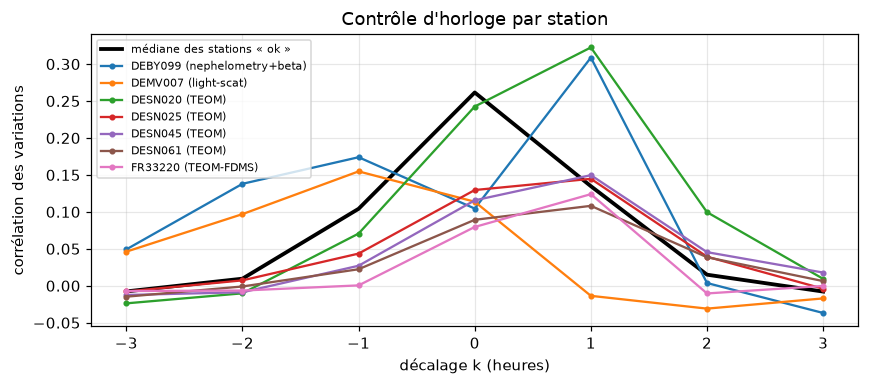

In [15]:
station_flags = pl.read_parquet(PAIRS / "clock_check_station.parquet")
station_corr = pl.read_parquet(PAIRS / "clock_station_correlations.parquet")
method = (
    pl.read_parquet(settings.paths.meta / "eea_stations_pm25.parquet")
    .select("station_code", "measurement_method")
    .unique("station_code")
)
bad = station_flags.filter(pl.col("clock_flag").is_in(["clock_mismatch", "instrument_lag"])).join(
    method, on="station_code", how="left"
)
print(
    bad.select(
        "station_code", "clock_flag", "measurement_method", "n_hours", "r_lag0", "best_lag_h", "r_best", "z"
    )
)
fig, ax = plt.subplots(figsize=(8, 3.6))
good = station_corr.join(
    station_flags.filter(pl.col("clock_flag") == "ok").select("station_code"), on="station_code"
)
typical = good.group_by("lag_h").agg(pl.col("pearson_r").median()).sort("lag_h")
ax.plot(typical["lag_h"], typical["pearson_r"], color="k", lw=2.5, label="médiane des stations « ok »")
flagged = station_corr.join(bad.select("station_code", "measurement_method"), on="station_code").sort("lag_h")
for (code_,), part in flagged.group_by("station_code", maintain_order=True):
    ax.plot(part["lag_h"], part["pearson_r"], marker=".", label=f"{code_} ({part['measurement_method'][0]})")
ax.set_xlabel("décalage k (heures)")
ax.set_ylabel("corrélation des variations")
ax.set_title("Contrôle d'horloge par station")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_horloge_stations.png")

In [16]:
pair_flags = pl.read_parquet(PAIRS / "clock_check.parquet")
pair_flags.group_by("clock_flag").agg(
    paires=pl.len(), heures=pl.col("n_hours").sum(), r_lag0_médian=pl.col("r_lag0").median().round(3)
).sort("clock_flag")

clock_flag,paires,heures,r_lag0_médian
str,u32,u32,f64
"""clock_mismatch""",12,91128,0.201
"""clock_unverifiable""",299,2261581,0.044
"""instrument_lag""",17,187772,0.22
"""ok""",1113,11040966,0.381


**Ce qu'on observe.** **La contre-épreuve valide la méthode.** Si on retire la correction `Start − 1 h`, le
test rejette 1 085 paires vérifiables sur 1 142 et 207 stations sur 216. Avec la correction, il signale **29 paires**
et **7 stations**. L'exemple de la paire 32200 montre pourquoi on travaille sur les variations : sur deux ans, ses
niveaux donnent 0,888 à $k = 0$ contre 0,884 à $k = +1$ (sur janvier 2025 seul, c'était 0,920 contre 0,921, et elle
était rejetée à tort), alors que ses variations culminent nettement à $k = 0$ (0,231 contre 0,181 et 0,118).

**5 des 7 stations signalées mesurent avec un TEOM** (4 en Saxe, DESN020/025/045/061, et FR33220 en TEOM-FDMS),
toutes à $k = +1$, avec une corrélation **répartie** entre 0 et +1 (DESN061 : 0,089 et 0,108) au lieu de chuter à 0
comme pour un vrai décalage, en hiver comme en été. C'est la réponse retardée de la microbalance (environ une
demi-heure), pas une erreur d'horloge : ces stations sont **gardées** (`instrument_lag`) et leur méthode devient une
variable. Restent **exclues** DEBY099 (+1 h net, z = 13, un seul capteur) et DEMV007 (−1 h, z = 3,7), inexpliquées
(24 283 heures), et **10 paires** en décalage individuel (70 038 heures). Enfin, **299 paires** sont « invérifiables » :
leurs variations horaires ne suivent pas la station (corrélation médiane 0,04). Elles sont gardées avec leur drapeau
`clock_flag` et comparées aux autres dans le notebook 04.

## 7. L'entonnoir complet et les heures-paires utilisables

**Ce qu'on fait.** Chaque heure de chaque segment de capteur reçoit un statut, dans l'ordre : heure du capteur
(mesures valides, complétude), station (segment apparié, valeur EEA valide), horloge (station puis paire), humidité
officielle. On compte à chaque règle les heures, capteurs, paires et stations perdus.

**Pourquoi.** C'est le bilan honnête : tout ce qui manque à la fin a une raison écrite.

In [17]:
pair_hours = pl.read_parquet(PAIRS / "pair_hours.parquet")
report._explain(report.pair_funnel(pair_hours), report.HOUR_REASONS)

step,raison,removed,remaining,capteurs_lost,capteurs_remaining,paires_lost,paires_remaining,stations_lost,stations_remaining
str,str,i64,i64,i64,i64,i64,i64,i64,i64
"""start""","""point de départ""",0,15668400,0,1399,0,1479,0,298
"""no_valid_reading""","""aucune mesure valide dans l'heure (raison dominante dans `main_flag`)""",230389,15438011,3,1396,4,1475,0,298
"""incomplete_hour""","""complétude < 75 % de la cadence propre du capteur""",800252,14637759,2,1394,8,1467,1,297
"""no_reference_station""","""segment de position sans station utilisable à ≤ 3 km""",42902,14594857,0,1394,19,1448,0,297
"""reference_not_downloaded""","""station de référence non téléchargée""",0,14594857,0,1394,0,1448,0,297
"""reference_missing""","""pas de valeur EEA PM2.5 à cette heure""",264171,14330686,0,1394,0,1448,0,297
"""reference_invalid""","""valeur EEA PM2.5 invalide (drapeau ou −999)""",410665,13920021,0,1394,5,1443,0,297
"""reference_not_verified""","""valeur EEA PM2.5 non vérifiée""",0,13920021,0,1394,0,1443,0,297
"""reference_negative_beyond_uncertainty""","""valeur EEA PM2.5 < −5 µg/m³""",3,13920018,0,1394,0,1443,0,297


In [18]:
print(report.usable_by(pair_hours, ["country", "distance_band"]))
print(report.usable_by(pair_hours, ["country", "station_type"]))
report.usable_by(pair_hours, ["country", "method_class"])

shape: (4, 8)
┌─────────┬───────────────┬───────────────┬────────┬──────────┬──────────┬────────────────────────────┬───────────────────┐
│ country ┆ distance_band ┆ heures_paires ┆ paires ┆ capteurs ┆ stations ┆ pct_humidité_locale_fiable ┆ pct_secours_météo │
│ ---     ┆ ---           ┆ ---           ┆ ---    ┆ ---      ┆ ---      ┆ ---                        ┆ ---               │
│ str     ┆ str           ┆ u32           ┆ u32    ┆ u32      ┆ u32      ┆ f64                        ┆ f64               │
╞═════════╪═══════════════╪═══════════════╪════════╪══════════╪══════════╪════════════════════════════╪═══════════════════╡
│ DE      ┆ far           ┆ 7162545       ┆ 709    ┆ 689      ┆ 187      ┆ 26.3                       ┆ 4.51              │
│ DE      ┆ near          ┆ 5558171       ┆ 577    ┆ 555      ┆ 177      ┆ 26.9                       ┆ 4.94              │
│ FR      ┆ far           ┆ 694585        ┆ 96     ┆ 92       ┆ 40       ┆ 33.5                       ┆ 0.03          

shape: (6, 8)
┌─────────┬──────────────┬───────────────┬────────┬──────────┬──────────┬────────────────────────────┬───────────────────┐
│ country ┆ station_type ┆ heures_paires ┆ paires ┆ capteurs ┆ stations ┆ pct_humidité_locale_fiable ┆ pct_secours_météo │
│ ---     ┆ ---          ┆ ---           ┆ ---    ┆ ---      ┆ ---      ┆ ---                        ┆ ---               │
│ str     ┆ str          ┆ u32           ┆ u32    ┆ u32      ┆ u32      ┆ f64                        ┆ f64               │
╞═════════╪══════════════╪═══════════════╪════════╪══════════╪══════════╪════════════════════════════╪═══════════════════╡
│ DE      ┆ background   ┆ 5480574       ┆ 549    ┆ 538      ┆ 130      ┆ 29.6                       ┆ 2.67              │
│ DE      ┆ industrial   ┆ 303186        ┆ 33     ┆ 33       ┆ 13       ┆ 24.8                       ┆ 6.75              │
│ DE      ┆ traffic      ┆ 6936956       ┆ 704    ┆ 678      ┆ 94       ┆ 24.3                       ┆ 6.21              │
│ 

country,method_class,heures_paires,paires,capteurs,stations,pct_humidité_locale_fiable,pct_secours_météo
str,str,u32,u32,u32,u32,f64,f64
"""DE""","""beta""",623319,55,55,10,19.0,0.49
"""DE""","""nephelometry_beta""",1969271,188,181,34,23.9,0.46
"""DE""","""optical""",9375432,968,932,183,26.9,6.24
"""DE""","""teom""",752694,75,75,10,36.2,0.03
"""FR""","""beta""",216811,40,38,17,41.2,0.0
"""FR""","""optical""",494799,59,57,21,31.4,0.04
"""FR""","""teom""",362684,43,42,17,40.5,0.01
"""FR""","""unknown""",27342,3,3,3,99.3,0.0


### 7.1 Le découpage par station pour la validation croisée

**Ce qu'on fait.** La colonne `cv_group` (= code de la station) sera le groupe de la validation croisée
(*GroupKFold*, étape 6). On vérifie combien de stations ont des capteurs dans les deux bandes de distance.

**Pourquoi.** Une station ne doit jamais être à la fois dans l'entraînement et dans un test, quelle que soit la
distance : sinon le modèle aurait déjà vu la pollution locale de la station qu'il prétend prédire.

shape: (3, 2)
┌──────────┬──────────┐
│ bandes   ┆ stations │
│ ---      ┆ ---      │
│ str      ┆ u32      │
╞══════════╪══════════╡
│ far+near ┆ 144      │
│ far      ┆ 83       │
│ near     ┆ 68       │
└──────────┴──────────┘


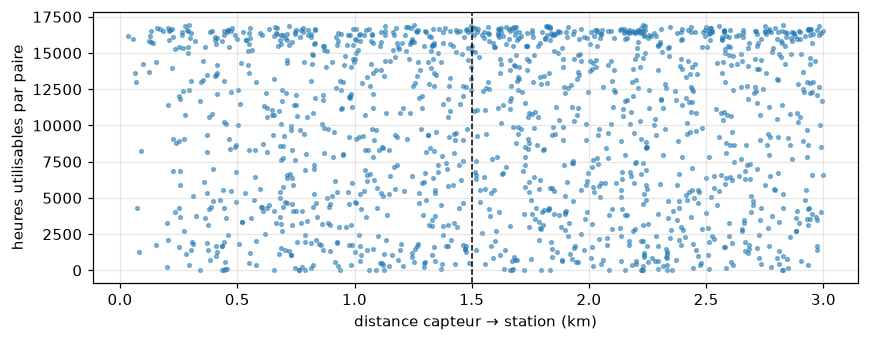

In [19]:
usable = pair_hours.filter(pl.col("status") == "ok")
bands = usable.group_by("cv_group").agg(bandes=pl.col("distance_band").unique().sort())
print(bands.with_columns(pl.col("bandes").list.join("+")).group_by("bandes").agg(stations=pl.len()))
fig, ax = plt.subplots(figsize=(8, 3.2))
per_pair = usable.group_by("pair_id").agg(heures=pl.len(), distance_km=pl.col("distance_km").first())
ax.scatter(per_pair["distance_km"], per_pair["heures"], s=6, alpha=0.5)
ax.axvline(settings.pairing.radius_train_km, color="k", ls="--", lw=1)
ax.set_xlabel("distance capteur → station (km)")
ax.set_ylabel("heures utilisables par paire")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_heures_par_paire.png")

**Ce qu'on observe.** Des 15,67 millions d'heures-capteur de départ, il reste **13,82 millions d'heures-paires
utilisables (88,2 %)**, sur **1 431 paires**, **1 382 capteurs** et **295 stations**. Les pertes, dans l'ordre :
heures du capteur (1,03 M : panne ou incomplétude), segment sans station (0,04 M), référence absente ou invalide
(0,67 M), horloge (0,09 M : 2 stations et 10 paires), humidité officielle absente (3 345 heures seulement grâce à la
station de secours). Par pays et bande : **Allemagne near 5,56 M** heures (577 paires, 177 stations), **Allemagne far
7,16 M** (709 paires), **France near 0,41 M** (49 paires), **France far 0,69 M** (96 paires). Les stations trafic font
55 % des heures allemandes. Par méthode de mesure, l'Allemagne est dominée par l'optique (9,38 M heures), puis le
néphélomètre + bêta (1,97 M), le TEOM (0,75 M) et la jauge bêta (0,62 M) ; la France est plus équilibrée (optique
0,49 M, TEOM 0,36 M, bêta 0,22 M). **144 stations** ont des capteurs utilisables dans les deux bandes : la validation
croisée devra les garder entières dans un même pli (`cv_group`).

## 8. Bilan de l'étape 3

- **Aucune ligne supprimée** : chaque mesure, heure et paire garde son statut ; l'entonnoir (`reports/funnel.md`) se
  recalcule à partir de ces statuts.
- **Particules** : 2,0 % des mesures écartées, uniquement par des règles physiques ou de cohérence, chacune justifiée
  par les données ; la règle « figé » ne vise plus l'air propre (codes de panne, ou station qui varie) ; la
  complétude suit la cadence propre de chaque capteur.
- **Segments** : 65 capteurs déplacés, appariés par segment ; 12 segments changent de station, 22 n'en ont plus.
- **Horloge** : contrôle automatique sur toutes les paires et toutes les stations, validé par contre-épreuve ;
  les 5 stations TEOM (réponse retardée) sont gardées, 2 stations et 10 paires sont exclues.
- **Humidité** : officielle en entrée principale (100 % des paires), sonde locale fiable ≈ 27 % du temps.
- **Résultat** : 13,82 millions d'heures-paires utilisables ; DE near 5,56 M, DE far 7,16 M, FR near 0,41 M,
  FR far 0,69 M ; méthode de mesure de chaque station disponible (`method_class`).
- **Pour l'étape 4** : le « avant » (cibles EPA sans correction), l'erreur brute selon l'humidité, la saison, le type
  de station, la méthode, la distance et l'âge, la forme de la relation, et les paires « invérifiables ».